# Handwritten Digit Recognition with Perceptron, ANN and CNN

# 1. Import libraries and set up the experiment

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility: use the same random seed when rerunning the notebook.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")


# 2. Load the Dataset

In [4]:
df = pd.read_csv("data/train.csv")
df_test = pd.read_csv("data/test.csv")

# 2.1 Visualize Dataset

In [5]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df.shape

(42000, 785)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [8]:
print("Missing values in training data:", df.isnull().sum().sum())
print("Missing values in test data:", df_test.isnull().sum().sum())
print("Duplicate training rows:", df.duplicated().sum())

Missing values in training data: 0
Missing values in test data: 0
Duplicate training rows: 0


# 3. Separate images and labels

In [19]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["label"]).to_numpy()
y = df["label"].to_numpy()

X_test = df_test.to_numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape)

Training: (33600, 784) (33600,)
Validation: (8400, 784) (8400,)
Test: (28000, 784)


## 3.1 Normalize and reshape

In [20]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train_img = X_train.reshape(-1, 28, 28, 1)
X_val_img = X_val.reshape(-1, 28, 28, 1)
X_test_img = X_test.reshape(-1, 28, 28, 1)

## 3.2 One-hot encoding

In [21]:
NUM_CLASSES = 10

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)

In [22]:
print("One-hot encoded label shape:", y_train_cat.shape)

One-hot encoded label shape: (33600, 10)


# 4. Build a Perceptron baseline

In [23]:
perceptron = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(NUM_CLASSES, activation="softmax")
], name="Perceptron_Baseline")

perceptron.summary()

Model: "Perceptron_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

# 4.1 Compile the Perceptron

In [24]:
perceptron.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

# 4.2 Train the Perceptron

In [25]:
history_percp = perceptron.fit(
    X_train_img, y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 414us/step - accuracy: 0.7678 - loss: 0.9876 - val_accuracy: 0.8545 - val_loss: 0.6260
Epoch 2/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step - accuracy: 0.8657 - loss: 0.5476 - val_accuracy: 0.8738 - val_loss: 0.4955
Epoch 3/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step - accuracy: 0.8789 - loss: 0.4672 - val_accuracy: 0.8813 - val_loss: 0.4427
Epoch 4/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step - accuracy: 0.8867 - loss: 0.4279 - val_accuracy: 0.8869 - val_loss: 0.4127
Epoch 5/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step - accuracy: 0.8918 - loss: 0.4035 - val_accuracy: 0.8923 - val_loss: 0.3929


# 4.3 Evaluate the Perceptron on unseen test data

In [29]:
_, acc_percp = perceptron.evaluate(
    X_val_img,
    y_val_cat,
    verbose=0
)

print(f"Perceptron validation accuracy: {acc_percp:.4%}")

Perceptron validation accuracy: 88.9643%


# 5. Build a fully connected ANN

In [31]:
ann = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(NUM_CLASSES, activation="softmax")
], name="ANN")

ann.summary()

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

## 5.1 Train the ANN

In [33]:
# Train the ANN using the same training/validation strategy.
history_ann = ann.fit(
    X_train_img, y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 2s 869us/step - accuracy: 0.9067 - loss: 0.3160 - val_accuracy: 0.9485 - val_loss: 0.1701
Epoch 2/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 838us/step - accuracy: 0.9604 - loss: 0.1328 - val_accuracy: 0.9574 - val_loss: 0.1431
Epoch 3/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 767us/step - accuracy: 0.9748 - loss: 0.0870 - val_accuracy: 0.9583 - val_loss: 0.1400
Epoch 4/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 750us/step - accuracy: 0.9826 - loss: 0.0612 - val_accuracy: 0.9577 - val_loss: 0.1472
Epoch 5/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 777us/step - accuracy: 0.9869 - loss: 0.0448 - val_accuracy: 0.9634 - val_loss: 0.1355


## 5.2 Evaluate the ANN

In [35]:
_, acc_ann = ann.evaluate(
    X_val_img,
    y_val_cat,
    verbose=0
)

print(f"ANN validation accuracy: {acc_ann:.4%}")

ANN validation accuracy: 96.6190%


# 6. Prepare images for the CNN

In [37]:
# Reshape images into CNN-compatible format

X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Testing:", X_test_cnn.shape)

Training: (33600, 28, 28, 1)
Validation: (8400, 28, 28, 1)
Testing: (28000, 28, 28, 1)


## 6.1 Design the Convolutional Neural Network

In [39]:
cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation="softmax")
], name="CNN")

cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 6.2 Compile the CNN

In [40]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

## 6.3 Train the CNN

In [41]:
history_cnn = cnn.fit(
    X_train_cnn,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(X_val_cnn, y_val_cat),
    verbose=1
)

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9012 - loss: 0.3251 - val_accuracy: 0.9732 - val_loss: 0.0863
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9671 - loss: 0.1086 - val_accuracy: 0.9821 - val_loss: 0.0577
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9765 - loss: 0.0807 - val_accuracy: 0.9824 - val_loss: 0.0540
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9804 - loss: 0.0629 - val_accuracy: 0.9860 - val_loss: 0.0449
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9834 - loss: 0.0513 - val_accuracy: 0.9875 - val_loss: 0.0408
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9861 - loss: 0.0453 - val_accuracy: 0.9867 - val_loss: 0.0433
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9873 - loss: 0.0406 - val_accuracy: 0.9876 - val_loss: 0.0430
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9882 - loss: 0.0361 - val_accuracy: 

## 6.4 Evaluate the CNN

In [44]:
_, acc_cnn = cnn.evaluate(
    X_val_cnn,
    y_val_cat,
    verbose=0
)

print(f"CNN Validation Accuracy: {acc_cnn:.4%}")

CNN Validation Accuracy: 98.9762%


# 7. Visualisation 

In [45]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

# Perceptron

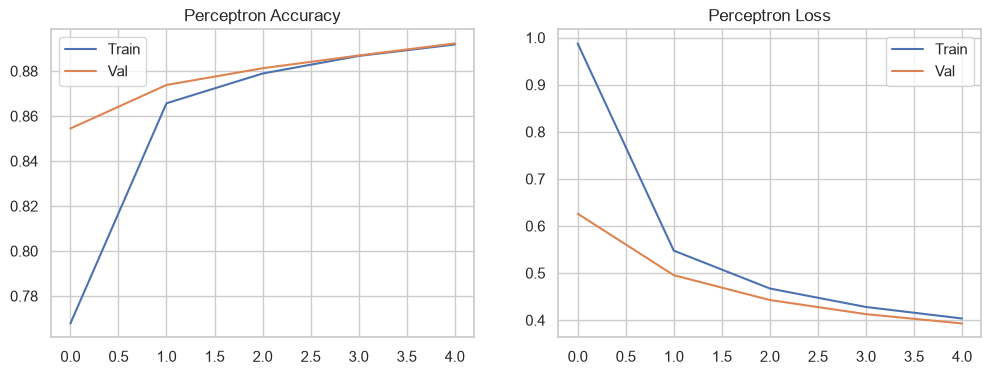

In [46]:
plot_training(history_percp, "Perceptron")

# ANN

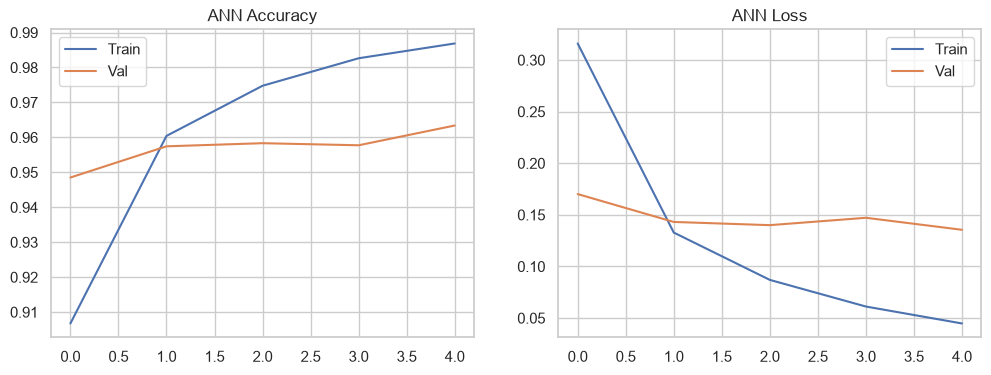

In [47]:
plot_training(history_ann, "ANN")

# CNN

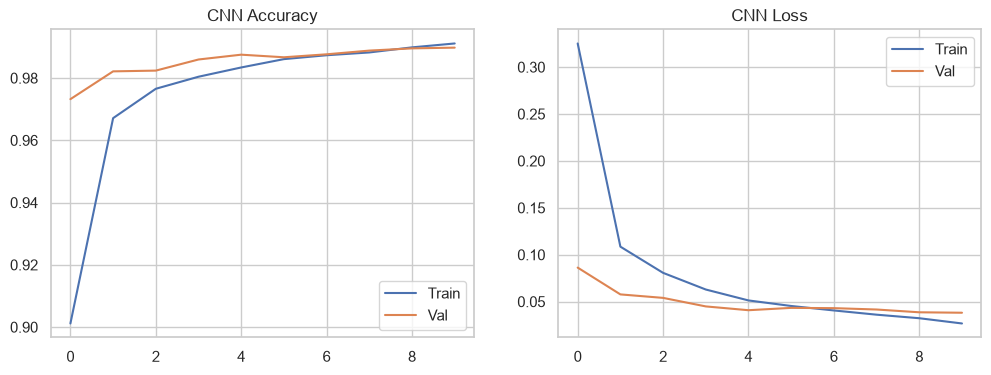

In [48]:
plot_training(history_cnn, "CNN")

# 8. Compare validation accuracy across models

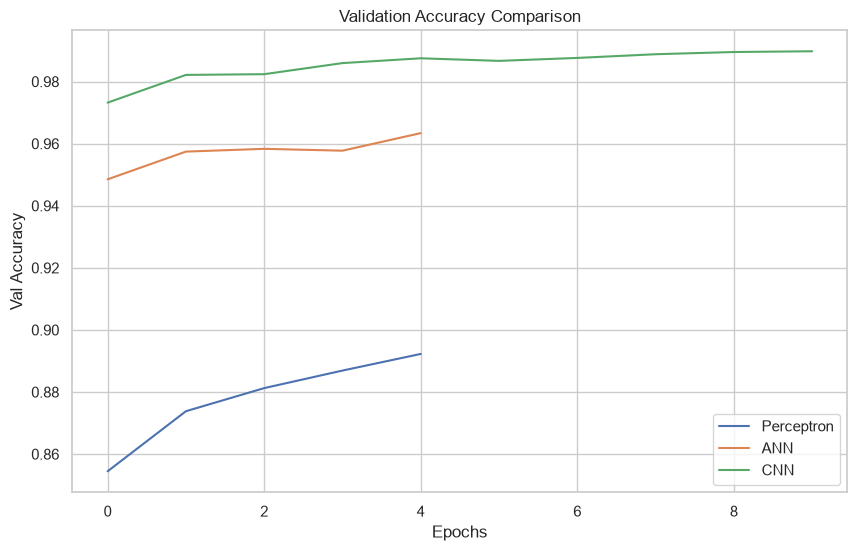

In [49]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

# 9. Compare predictions on the same images

In [50]:
def show_side_by_side(models, model_names, X_images, X_cnn_images, y_true, n=5):
    # Select random examples so the comparison is not always identical.
    rng = np.random.default_rng(SEED)
    indices = rng.choice(len(X_images), size=n, replace=False)

    plt.figure(figsize=(15, 5))
    for position, idx in enumerate(indices):
        image = X_images[idx]

        plt.subplot(2, n, position + 1)
        plt.imshow(image, cmap="gray")
        plt.title(f"True: {y_true[idx]}")
        plt.axis("off")

        predictions = []
        for model, model_name in zip(models, model_names):
            model_input = (
                X_cnn_images[idx:idx+1]
                if model_name == "CNN"
                else X_images[idx:idx+1]
            )
            probabilities = model.predict(model_input, verbose=0)
            predictions.append(int(np.argmax(probabilities[0])))

        plt.subplot(2, n, n + position + 1)
        plt.text(
            0.05, 0.5,
            "\n".join(
                f"{name}: {prediction}"
                for name, prediction in zip(model_names, predictions)
            ),
            fontsize=11,
            va="center"
        )
        plt.axis("off")

    plt.suptitle("How do Perceptron, ANN and CNN classify the same images?", y=1.02)
    plt.tight_layout()
    plt.show()

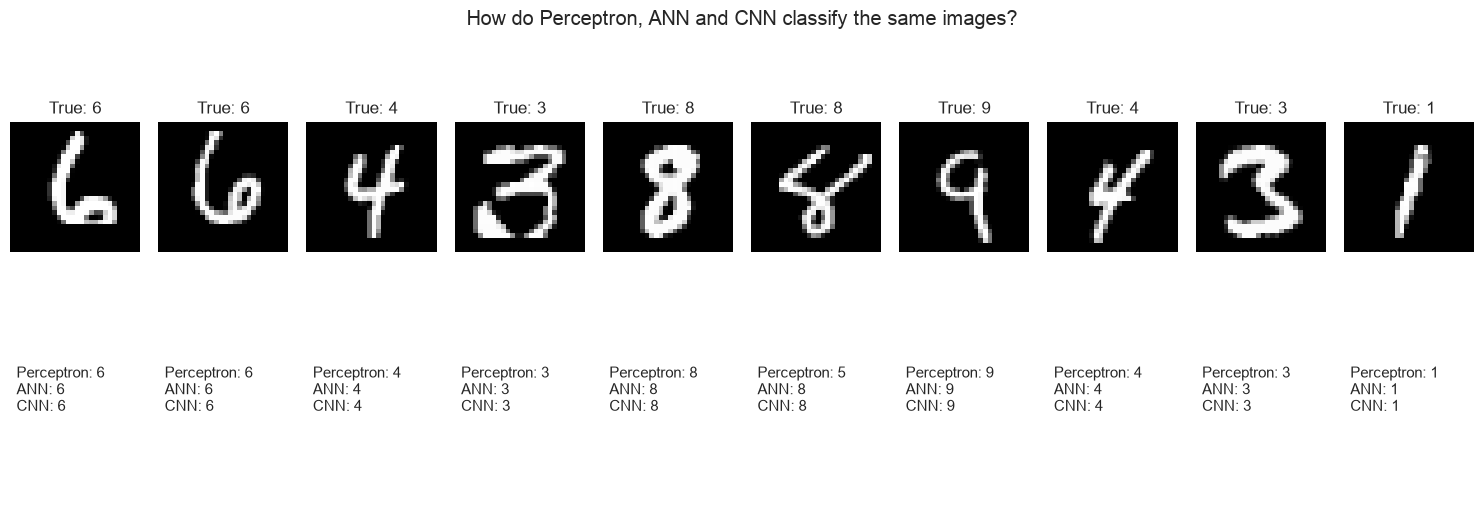

In [56]:
show_side_by_side(
    [perceptron, ann, cnn],
    ["Perceptron", "ANN", "CNN"],
    X_val_img,
    X_val_cnn,
    y_val,
    10
)

# 10. Inspect the CNN confusion matrix

CNN Classification Report:
              precision    recall  f1-score   support

           0     0.9904    0.9952    0.9928       827
           1     0.9968    0.9947    0.9957       937
           2     0.9857    0.9928    0.9893       835
           3     0.9919    0.9828    0.9873       870
           4     0.9939    0.9951    0.9945       814
           5     0.9868    0.9855    0.9862       759
           6     0.9916    0.9952    0.9934       827
           7     0.9842    0.9932    0.9887       880
           8     0.9913    0.9791    0.9851       813
           9     0.9845    0.9833    0.9839       838

    accuracy                         0.9898      8400
   macro avg     0.9897    0.9897    0.9897      8400
weighted avg     0.9898    0.9898    0.9898      8400



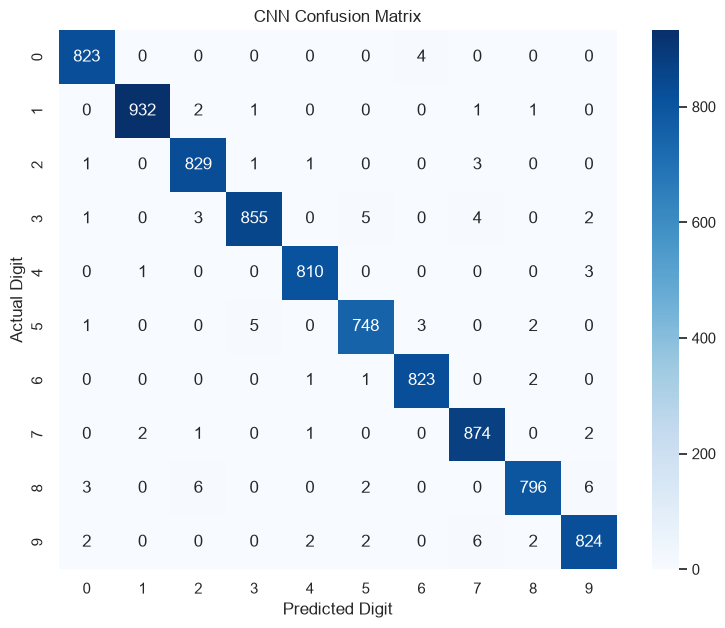

In [59]:


# Generate predictions
y_pred_cnn = np.argmax(
    cnn.predict(X_val_cnn, verbose=0),
    axis=1
)

# Classification Report
print("CNN Classification Report:")
print(classification_report(
    y_val,
    y_pred_cnn,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_val, y_pred_cnn)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

# 11. Compare validation accuracy of all three models

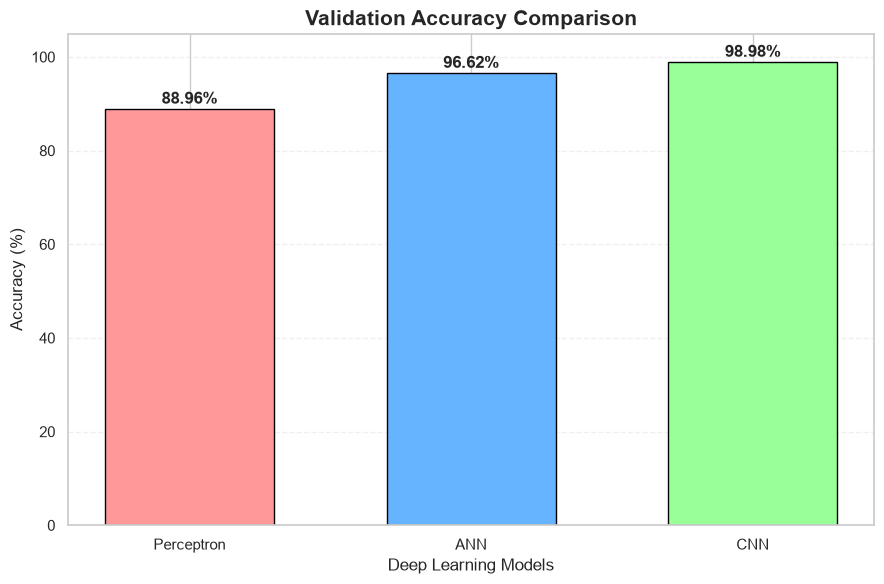

In [60]:


final_accs = [
    acc_percp * 100,
    acc_ann * 100,
    acc_cnn * 100
]

models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    models,
    final_accs,
    color=["#ff9999", "#66b3ff", "#99ff99"],
    edgecolor="black",
    width=0.6
)

plt.title("Validation Accuracy Comparison", fontsize=15, fontweight="bold")
plt.ylabel("Accuracy (%)", fontsize=12)
plt.xlabel("Deep Learning Models", fontsize=12)

for bar, acc in zip(bars, final_accs):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{acc:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()